# Lead-lag network of Managed Money across 18 commodity futures

**Question.** Does Managed Money (MM) flow in one market lead flow in another, and is that useful? We build the directed network of Bennett, Cucuringu and Reinert (2022), test it hard, and ask whether it forecasts.

**Findings.** Mostly negative, and we report them that way.

- **There is little lead-lag structure across 18 markets.** The paper's own metrics do not reject on any series (global p of 0.37-0.97 for ccf-auc and 0.15-0.50 for ccf-lag1). A signed-sum metric does reject on flows (p of 0.03 or less), but after filtering at most two pairs can be located.
- **The naive network is mostly an artefact.** Raw flow on the signed-sum metric gives 28 links out of 153. Keeping each market's own dynamics in the null leaves 2, and filtered discretionary flow leaves none. On ccf-lag1, filtered discretionary flow has 4 links at BH 10%, none at 5% or under a block null.
- **The network is not stable.** Sign persistence across three periods is at chance (38-44 pairs against 38 expected), and leadingness ranks and clusters change from period to period.
- **One structure deserves follow-up: crude leads products by a week in discretionary flow.** Mean S is 0.097 (p = 0.001, or 0.063 under a block null), all six pairs are positive, and control groups and returns show nothing. The aggregation is post hoc and it has no out-of-sample value.
- **The 2026 rotation shows up in only one measure.** Brent's April-June liquidation is large (-281k contracts, 1.5th percentile). Inflows into gasoil and RBOB appear only in the NN-error measure (+59k and +29k), and are near zero in raw flow and the price rule. The size of the shift is ordinary (21st-68th percentile).
- **The network does not forecast.** Against the 5.87% own-lag benchmark, adding it gives 5.40%, and shuffled node labels do about as well. On 18 markets prices add (5.89% to 7.56%) and the network does not. It does not help the NN's 44.90% nowcast either, and a neural version loses to the linear one.

**Limits.** These tests only find strong single links (a planted 0.10 is found 7% of the time, a planted 0.30 99%), so weak links are not excluded. Discretionary flow here is a linear residual with a full-sample fit, and it is blind when signals are capped. Weekly Tuesday positions cannot see faster lead-lag. Everything is association, and no cause is tested.

**Our view.** We would not use this as a forecasting feature. It works as a diagnostic, mainly to show how much apparent lead-lag in MM comes from own persistence.

## Setup

In [1]:
import os

for variable in ("VECLIB_MAXIMUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels.api as sm
import torch
from IPython.display import display
from matplotlib.lines import Line2D
from scipy import stats
from torch import nn as tnn

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "working_ideas" else Path.cwd()
sys.path[:0] = [str(REPO_ROOT / "paper_replication" / "src"), str(REPO_ROOT / "working_ideas" / "src")]
import commodity_trend as ct
import leadlag as ll
import sg_cta as sg
from paper_replication.config import ReplicationConfig
from paper_replication.model import reaction

OUTPUT = REPO_ROOT / "paper_replication" / "outputs" / "leadlag_network"
OUTPUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 200, "display.float_format", lambda v: f"{v:,.3f}")
M, OIL, OILGAS = ll.MARKETS, ll.OIL, ll.OILGAS
CRUDE, PRODUCTS = ["BRENT", "WTI"], ["GASOIL", "HEATOIL", "RBOB"]
COLOR = {"oil": "#2a78d6", "gas": "#eb6834", "metals": "#1baf7a", "grains": "#eda100", "softs": "#e87ba4"}
INK, MUTED, SOFT = "#0b0b0b", "#52514e", "#b9b8b2"

## Data

$Y^i_t$ is market $i$'s weekly Managed Money (MM) flow, in one of three forms, all on the same 790 weeks from 2011-07-12, once all 18 markets have a scale.

- **ret**: the week's return over its lagged 52-week standard deviation.
- **raw**: the change in MM net position over its lagged 52-week standard deviation.
- **disc**: the residual of raw flow on a constant, the market's own signal flow from the SG replication, and its own return. This is "discretionary" flow in a loose sense: it is whatever a linear price-and-trend rule leaves over. The fit uses the full sample, so it is descriptive and not usable for forecasting.

The suffix **_pw** means own-AR prewhitened (Haugh, 1976). Bennett, Cucuringu and Reinert (2022) warn that autocorrelation combined with co-movement creates spurious lead-lag, and MM flows have both. Prewhitening removes each market's own persistence, so it matters here. COT data for week $t$ are published on the Friday of week $t$.

In [2]:
T = ct.trend_panel(REPO_ROOT / "working_ideas" / "data_required", REPO_ROOT / "paper_replication" / "data_required", ll.END)
Y, disc_fit = ll.build_series(T)
assert not any(Y[name].isna().any().any() for name in ("sret", "raw", "disc", "sf")), "gaps in the panel"
frames, ar_tables = {"ret": Y["sret"], "raw": Y["raw"], "disc": Y["disc"]}, {}
for name in ("ret", "raw", "disc"):
    frames[f"{name}_pw"], ar_tables[name] = ll.prewhiten(frames[name])
series = {name: frame.to_numpy() for name, frame in frames.items()}
ar1 = lambda frame: frame.apply(lambda column: column.autocorr(1))
summary = pd.DataFrame({"R² of the price-and-trend rule": disc_fit["R2"], "On signal flow": disc_fit["b_signal"], "On return": disc_fit["b_ret"],
                        "AR(1), raw": ar1(frames["raw"]), "AR(1), disc": ar1(frames["disc"]), "AR(1), disc_pw": ar1(frames["disc_pw"]),
                        "AR order, disc": ar_tables["disc"]["p"]})
print(f"{len(frames['raw'])} weeks, {frames['raw'].index[0]:%Y-%m-%d} to {frames['raw'].index[-1]:%Y-%m-%d}; prewhitened series: {len(frames['disc_pw'])} weeks")
display(summary)

rng = np.random.default_rng(1)
planted = rng.standard_normal((800, 3))
planted[1:, 1] += 0.5 * planted[:-1, 0]
S_planted = ll.all_metrics(planted)
print("Check on simulated data, market 0 leads market 1: S[0, 1] =", {key: round(float(S_planted[key][0, 1]), 3) for key in ("auc", "auc_c", "lag1", "sum", "sig")},
      "; S[0, 2] =", {key: round(float(S_planted[key][0, 2]), 3) for key in ("auc_c", "lag1", "sum")})

790 weeks, 2011-07-12 to 2026-08-25; prewhitened series: 782 weeks


,R² of the price-and-trend rule,On signal flow,On return,"AR(1), raw","AR(1), disc","AR(1), disc_pw","AR order, disc"
BRENT,0.320,0.355,0.238,0.228,0.152,-0.005,1
WTI,0.323,0.418,0.149,0.179,0.143,0.006,1
GASOIL,0.313,0.386,0.193,0.311,0.220,0.015,1
HEATOIL,0.231,0.358,0.130,0.158,0.064,0.063,0
RBOB,0.250,0.291,0.224,0.171,0.119,0.003,1
NATGAS,0.297,0.254,0.341,0.237,0.146,0.004,1
GC,0.432,0.320,0.361,0.173,0.093,0.004,1
SI,0.401,0.353,0.285,0.291,0.177,-0.004,4
PL,0.418,0.307,0.382,0.266,0.162,0.013,1
PA,0.362,0.187,0.427,0.248,0.171,0.009,1


Check on simulated data, market 0 leads market 1: S[0, 1] = {'auc': 0.735, 'auc_c': 0.47, 'lag1': 0.502, 'sum': 0.657, 'sig': 0.635} ; S[0, 2] = {'auc_c': -0.248, 'lag1': -0.058, 'sum': -0.132}


**Reading.** The price-and-trend rule explains 23-46% of raw flow. Flow is persistent: raw AR(1) runs from 0.15 to 0.35 across markets and discretionary AR(1) from 0.01 to 0.26. Prewhitening takes it to about zero (at most 0.06). On simulated data all five metrics give the planted link the right sign. The unrelated pair also shows why we distrust ccf-auc: it reaches -0.25 by chance, as a ratio of small sums, while ccf-lag1 is -0.06.

## 1. The lead-lag matrix

With $\mathrm{ccf}^{ij}(l) = \mathrm{corr}(Y^i_{t-l}, Y^j_t)$, $S_{ij} > 0$ says $i$ leads $j$. We use three forms.

- **ccf-lag1**: $S_{ij} = \mathrm{ccf}^{ij}(1) - \mathrm{ccf}^{ij}(-1)$.
- **ccf-auc**, the paper's main metric, built on $I_{ij} = \sum_{l=1}^{4} |\mathrm{ccf}^{ij}(l)|$. As defined in the paper every $|S_{ij}|$ is at least 0.5, so the graph is complete by construction. We use the centred form $(I_{ij} - I_{ji})/(I_{ij} + I_{ji})$, which carries the same sign.
- **signed sum**: $\sum_{l=1}^{4} [\mathrm{ccf}^{ij}(l) - \mathrm{ccf}^{ij}(-l)]$, which accumulates a slow directional effect that lag 1 would miss.

First: how much of the MM matrix is just the returns matrix?

,"ccf-auc, centred",ccf-lag1,Signed sum
Correlation across the 153 pairs,,,
raw vs ret,0.013,0.291,0.125
disc vs ret,-0.051,0.084,-0.054
raw_pw vs ret_pw,0.045,0.375,0.164
disc_pw vs ret_pw,0.038,0.091,-0.052
disc_pw vs raw_pw,0.270,0.658,0.797


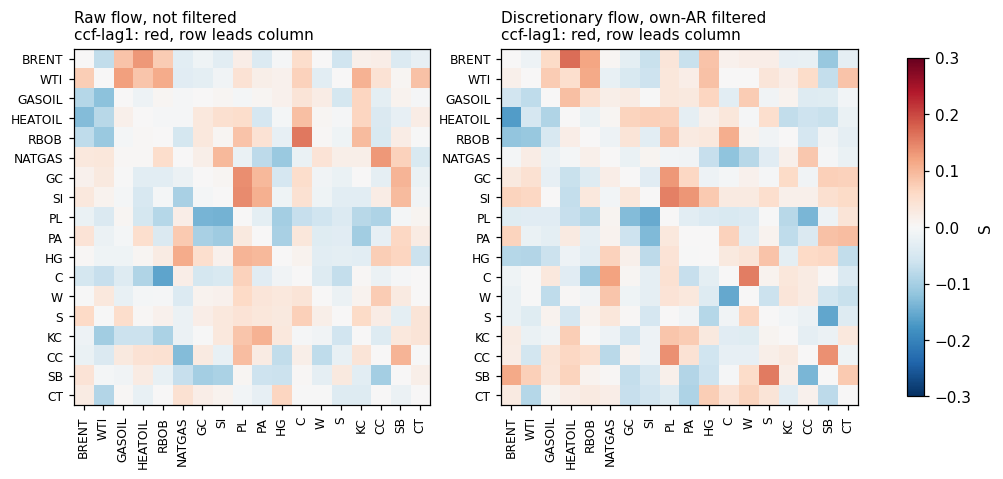

In [3]:
metrics = {name: ll.all_metrics(values) for name, values in series.items()}
rows = []
for a, b in [("raw", "ret"), ("disc", "ret"), ("raw_pw", "ret_pw"), ("disc_pw", "ret_pw"), ("disc_pw", "raw_pw")]:
    row = {"Pair": f"{a} vs {b}"}
    for key, label in {"auc_c": "ccf-auc, centred", "lag1": "ccf-lag1", "sum": "Signed sum"}.items():
        row[label] = np.corrcoef(ll.upper(metrics[a][key]), ll.upper(metrics[b][key]))[0, 1]
    rows.append(row)
display(pd.DataFrame(rows).set_index("Pair").rename_axis("Correlation across the 153 pairs"))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
for ax, (name, title) in zip(axes, {"raw": "Raw flow, not filtered", "disc_pw": "Discretionary flow, own-AR filtered"}.items()):
    image = ax.imshow(metrics[name]["lag1"], vmin=-0.3, vmax=0.3, cmap="RdBu_r")
    ax.set_xticks(range(18), M, rotation=90, fontsize=8)
    ax.set_yticks(range(18), M, fontsize=8)
    ax.set_title(f"{title}\nccf-lag1: red, row leads column", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(True)
fig.colorbar(image, ax=axes, shrink=0.8, label="S")
fig.savefig(OUTPUT / "leadlag_matrices.png", dpi=170, bbox_inches="tight")
plt.show()

**Reading.** Raw flow's lead-lag partly mirrors the returns matrix (0.29 on ccf-lag1, 0.38 after filtering), as expected since MM follows prices. For discretionary flow that link is gone: 0.08-0.09 on ccf-lag1 and about zero on the other two metrics. So whatever lead-lag discretionary flow has, it is not price lead-lag passed through.

## 2. Is there any lead-lag structure at all?

Before reading a network off the matrix we run the paper's global test: is the largest eigenvalue of the Hermitian matrix $iS$ bigger than it would be if the weeks were shuffled? Then we test each of the 153 pairs and keep those surviving Benjamini-Hochberg (BH). We try several nulls, because a plain row shuffle also destroys own persistence.

- **iid**: weeks shuffled jointly, the paper's null.
- **sieve**: each market keeps its own AR dynamics and the co-movement across markets, and only cross-lags are destroyed. This asks whether raw flow has lead-lag beyond own persistence.
- **block4**: blocks of 4 weeks in random order. It keeps short lags inside blocks, so it has low power by design.
- **local13**: weeks shuffled within 13-week blocks, which keeps slow volatility regimes.

In [4]:
RUNS = [(name, null, 5000) for name, null in [("raw", "iid"), ("raw", "sieve"), ("raw_pw", "iid"), ("disc", "iid"), ("disc", "sieve"), ("disc_pw", "iid"),
                                              ("disc_pw", "block4"), ("disc_pw", "local13"), ("ret_pw", "iid")]]
draws, rows = {}, []
for name, null, n_draws in RUNS:
    extra = {}
    if null == "sieve":
        residuals, table = frames[f"{name}_pw"].to_numpy(), ar_tables[name]
        extra = dict(residuals=residuals, ar_table=[(table["c"].iloc[k], table["phi"].iloc[k]) for k in range(18)])
    draws[name, null] = ll.permutation_draws(series[name], n_draws, null, **extra)
    for key, label in {"auc_c": "ccf-auc, centred", "lag1": "ccf-lag1", "sum": "Signed sum"}.items():
        S = metrics[name][key]
        p = ll.pair_p(S, draws[name, null][key])
        rows.append({"Series": name, "Null": null, "Metric": label, "Draws": n_draws, "Global p": ll.global_p(S, draws[name, null][key]),
                     "Links, BH 10%": ll.bh(p, 0.10).sum(), "Links, BH 5%": ll.bh(p, 0.05).sum()})
tests = pd.DataFrame(rows).set_index(["Series", "Null", "Metric"])
tests.assign(**{"Global p": tests["Global p"].map("{:.4f}".format)})

Draws Global p  Links, BH 10%  Links, BH 5%
Series  Null    Metric                                                       
raw     iid     ccf-auc, centred   5000   0.6675              0             0
                ccf-lag1           5000   0.1862              0             0
                Signed sum         5000   0.0002             28            19
        sieve   ccf-auc, centred   5000   0.8908              0             0
                ccf-lag1           5000   0.2761              0             0
                Signed sum         5000   0.0232              2             1
raw_pw  iid     ccf-auc, centred   5000   0.7504              0             0
                ccf-lag1           5000   0.3447              2             0
                Signed sum         5000   0.0114              2             0
disc    iid     ccf-auc, centred   5000   0.9022              0             0
                ccf-lag1           5000   0.2266              1             0
                Signed sum         5000   0.0004             19            13
        sieve   ccf-auc, centred   5000   0.9682              0             0
                ccf-lag1           5000   0.3183              1             0
                Signed sum         5000   0.0246              0             0
disc_pw iid     ccf-auc, centred   5000   0.8266              0             0
                ccf-lag1           5000   0.2603              4             0
                Signed sum         5000   0.0098              0             0
        block4  ccf-auc, centred   5000   0.7876              0             0
                ccf-lag1           5000   0.5019              0             0
                Signed sum         5000   0.0274              1             0
        local13 ccf-auc, centred   5000   0.8302              0             0
                ccf-lag1           5000   0.3681              2             0
                Signed sum         5000   0.0146              0             0
ret_pw  iid     ccf-auc, centred   5000   0.3697              0             0
                ccf-lag1           5000   0.1508              1             1
                Signed sum         5000   0.7756              1             0

**Reading.** This is the first main result, and it is mostly a null.

- **The paper's own metrics find nothing on 18 markets.** Across all nine runs the global p is 0.37-0.97 for ccf-auc and 0.15-0.50 for ccf-lag1.
- **The signed sum rejects on flows but not on returns.** The p-value is 0.03 or less on every flow row and 0.78 on filtered returns. But the rejection cannot be located: on filtered discretionary flow no pair survives BH 10% under the iid or local13 nulls, and one under block4.
- **Most naive links are own persistence.** Raw flow gives 28 links (19 at 5%), and the sieve null, which keeps own dynamics and co-movement, leaves 2 (1 at 5%). Unfiltered discretionary flow goes from 19 links to 0.

## 3. The network

We build the directed graph with an edge $i \to j$ when $i$ leads $j$ and the pair survives BH at 10% under the iid null. Node area shows leadingness, the row mean of $S$. The left panel is what a naive reading gives: raw flow with no filtering, on the signed sum. The right panel removes price, trend and own persistence first, on ccf-lag1. The panels use different metrics, so they are not a before-and-after of one statistic.

Naive graph: 28 links; the same statistic against the sieve null: 2 links


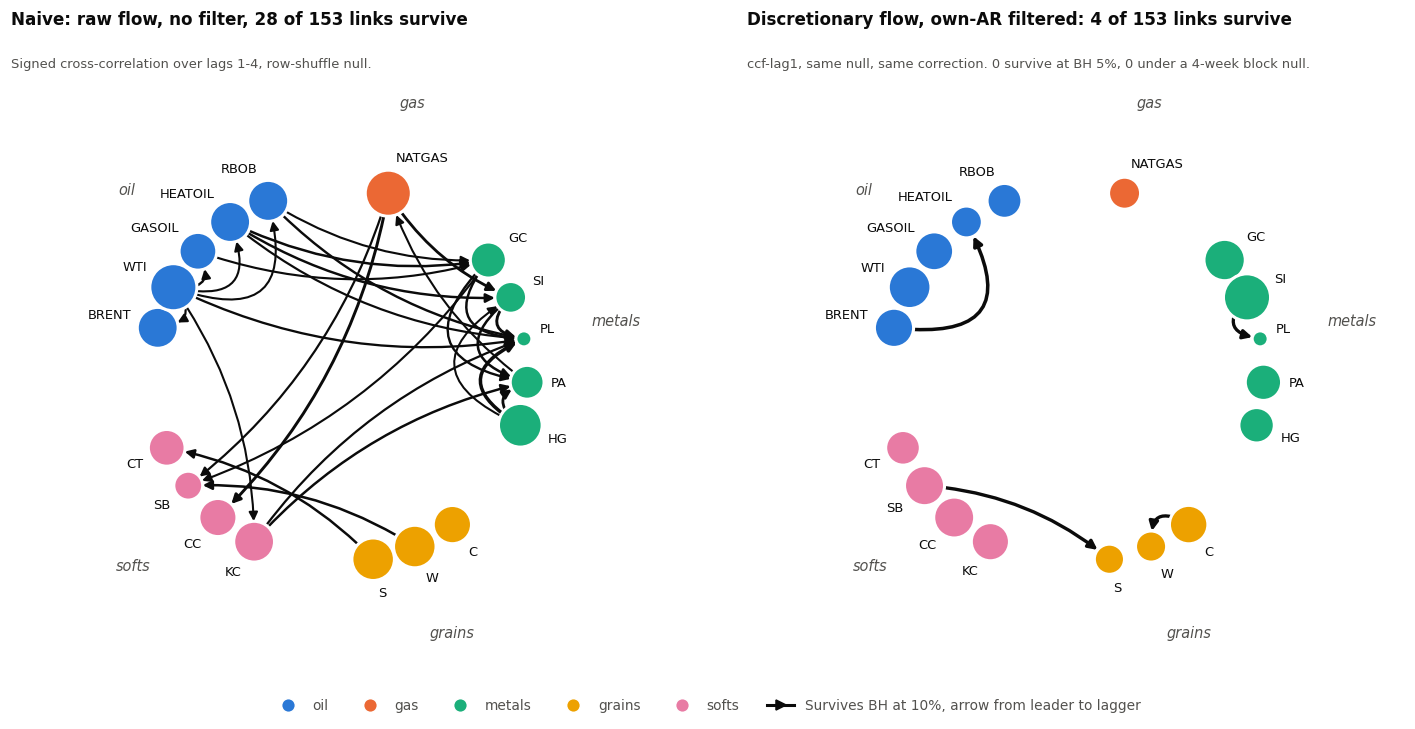

,Leader,Lagger,|S|,p,BH q,2011-2015,2016-2020,2021-2025,"p, block4","p, local13"
0,BRENT,HEATOIL,0.167,0.0004,0.054,0.297,-0.020,0.223,0.065,0.001
3,SB,S,0.156,0.0012,0.054,0.242,0.143,0.122,0.147,0.001
2,C,W,0.154,0.0008,0.054,0.139,0.277,0.102,0.104,0.003
1,SI,PL,0.151,0.0014,0.054,0.275,0.234,-0.082,0.148,0.002


,SI,WTI,GC,CC,SB,BRENT,GASOIL,C,KC,PA,HG,RBOB,CT,NATGAS,HEATOIL,W,S,PL
"Leadingness, disc_pw",0.042,0.023,0.018,0.016,0.013,0.009,0.008,0.007,0.005,-0.001,-0.004,-0.006,-0.007,-0.015,-0.016,-0.018,-0.021,-0.052


In [5]:
SECTORS = ["oil", "gas", "metals", "grains", "softs"]


def ring_positions(gap=0.42, start=np.pi * 0.92):
    step = (2 * np.pi - gap * len(SECTORS)) / len(M)
    position, middle, angle = {}, {}, start
    for sector in SECTORS:
        first = angle
        for market in [m for m in M if ll.SECTOR[m] == sector]:
            position[market] = (np.cos(angle), np.sin(angle))
            angle -= step
        middle[sector] = (first + angle + step) / 2
        angle -= gap
    return position, middle


def arc(p, q, within):
    """An arc bowing toward the centre of the ring, more strongly between neighbours in a sector."""
    r = 0.95 if within else 0.16
    (x1, y1), (x2, y2) = p, q
    mx, my, dx, dy = (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1
    return f"arc3,rad={r if (mx + r * dy) ** 2 + (my - r * dx) ** 2 < (mx - r * dy) ** 2 + (my + r * dx) ** 2 else -r}"


def draw_network(ax, G, title, subtitle):
    position, middle = ring_positions()
    lead = np.array([G.nodes[m]["leadingness"] for m in M])
    area = 110 + 840 * (lead - lead.min()) / (lead.max() - lead.min())
    sizes = dict(zip(M, area))
    top = max([d["weight"] for *_, d in G.edges(data=True)], default=1.0)
    for a, b, d in G.edges(data=True):
        nx.draw_networkx_edges(G, position, ax=ax, edgelist=[(a, b)], nodelist=M, node_size=list(area), edge_color=INK, width=0.7 + 1.6 * d["weight"] / top,
                               arrows=True, arrowstyle="-|>", arrowsize=12, connectionstyle=arc(position[a], position[b], ll.SECTOR[a] == ll.SECTOR[b]))
    nx.draw_networkx_nodes(G, position, ax=ax, nodelist=M, node_size=list(area), node_color=[COLOR[ll.SECTOR[m]] for m in M], edgecolors="white", linewidths=2)
    for market, (x, y) in position.items():
        offset = 1.05 + 0.0035 * np.sqrt(sizes[market])
        ax.text(x * offset, y * offset, market, fontsize=8.5, color=INK, ha="left" if x > 0.12 else "right" if x < -0.12 else "center",
                va="bottom" if y > 0.12 else "top" if y < -0.12 else "center")
    for sector, angle in middle.items():
        ax.text(1.5 * np.cos(angle), 1.5 * np.sin(angle), sector, ha="center", va="center", fontsize=9.5, color=MUTED, style="italic")
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=30, fontweight="semibold")
    ax.text(0, 1.0, subtitle, transform=ax.transAxes, fontsize=8.5, color=MUTED, va="bottom", linespacing=1.3)
    ax.set(xlim=(-1.75, 1.75), ylim=(-1.62, 1.62), aspect="equal")
    ax.axis("off")


S_raw, S_disc = metrics["raw"]["sum"], metrics["disc_pw"]["lag1"]
G_raw = ll.leadlag_graph(S_raw, M, ll.pair_p(S_raw, draws["raw", "iid"]["sum"]))
G_disc = ll.leadlag_graph(S_disc, M, ll.pair_p(S_disc, draws["disc_pw", "iid"]["lag1"]))
p_raw_sieve = ll.pair_p(S_raw, draws["raw", "sieve"]["sum"])
print(f"Naive graph: {G_raw.number_of_edges()} links; the same statistic against the sieve null: {ll.bh(p_raw_sieve, 0.10).sum()} links")
fig, axes = plt.subplots(1, 2, figsize=(13.6, 7.0))
draw_network(axes[0], G_raw, f"Naive: raw flow, no filter, {G_raw.number_of_edges()} of 153 links survive", "Signed cross-correlation over lags 1-4, row-shuffle null.")
p_disc = ll.pair_p(S_disc, draws["disc_pw", "iid"]["lag1"])
draw_network(axes[1], G_disc, f"Discretionary flow, own-AR filtered: {G_disc.number_of_edges()} of 153 links survive",
             f"ccf-lag1, same null, same correction. {ll.bh(p_disc, 0.05).sum()} survive at BH 5%, "
             f"{ll.bh(ll.pair_p(S_disc, draws['disc_pw', 'block4']['lag1']), 0.10).sum()} under a 4-week block null.")
handles = [Line2D([], [], marker="o", ls="", ms=9, mfc=COLOR[s], mec="white", label=s) for s in SECTORS]
handles.append(Line2D([], [], color=INK, lw=2, marker=">", ms=6, label="Survives BH at 10%, arrow from leader to lagger"))
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=9, labelcolor=MUTED, bbox_to_anchor=(0.5, 0.02))
fig.subplots_adjust(left=0.015, right=0.985, top=0.87, bottom=0.08, wspace=0.03)
fig.savefig(OUTPUT / "network_naive_vs_filtered.png", dpi=170)
plt.show()

survivors = ll.edge_table(G_disc)
for period, (start, end) in ll.PERIODS.items():
    S_period = ll.from_ccf(ll.ccf_pearson(frames["disc_pw"].loc[start:end].to_numpy(), 1))["lag1"]
    survivors[period] = [S_period[M.index(a), M.index(b)] for a, b in zip(survivors["Leader"], survivors["Lagger"])]
for null in ("block4", "local13"):
    p_null = ll.pair_p(S_disc, draws["disc_pw", null]["lag1"])
    survivors[f"p, {null}"] = [p_null[list(zip(*np.triu_indices(18, 1))).index(tuple(sorted((M.index(a), M.index(b)))))] for a, b in zip(survivors["Leader"], survivors["Lagger"])]
display(survivors.assign(p=survivors["p"].map("{:.4f}".format)))
pd.Series({m: G_disc.nodes[m]["leadingness"] for m in M}).sort_values(ascending=False).round(3).to_frame("Leadingness, disc_pw").T

**Reading.** We read the two metrics separately. On the signed sum, raw flow's 28 links fall to 2 under the sieve null, and filtered discretionary flow has none. On ccf-lag1, raw flow has no links and filtered discretionary flow has 4, so here filtering sharpens lag-1 links rather than removing them. Those 4 are fragile. All sit at BH 10% only (q = 0.054), none survives at 5%, and none reaches 5% under the block null (p of 0.065-0.148), though all do under local13 (0.001-0.003). Two keep the same sign in all three periods: sugar to soybeans and corn to wheat. Two flip: Brent to heating oil (-0.02 in 2016-2020) and silver to platinum (-0.08 in 2021-2025). With BH at 10%, some false links among those four are to be expected.

A null needs a power check. How strong would a single true link have to be for this procedure to find it? We plant one link $Y^j_t \leftarrow b\,Y^i_{t-1}$ in the filtered data and count how often it survives BH at 10% across the 153 pairs (normal approximation to the permutation p-value, 500 draws).

In [6]:
base_values = series["disc_pw"]
base_values = (base_values - base_values.mean(0)) / base_values.std(0)
rng = np.random.default_rng(11)
upper_i, upper_j = np.triu_indices(18, 1)
se = np.sqrt(2 / len(base_values))
rows = []
for b in (0.05, 0.10, 0.15, 0.20, 0.30):
    found = 0
    for _ in range(500):
        i, j = rng.choice(18, 2, replace=False)
        shuffled = base_values[rng.permutation(len(base_values))].copy()
        shuffled[1:, j] += b * shuffled[:-1, i]
        S = ll.from_ccf(ll.ccf_pearson(shuffled, 1))["lag1"]
        keep = ll.bh(2 * stats.norm.sf(np.abs(ll.upper(S)) / se), 0.10)
        pair = np.flatnonzero((upper_i == min(i, j)) & (upper_j == max(i, j)))[0]
        found += keep[pair] and np.sign(ll.upper(S)[pair]) == (1 if i < j else -1)
    rows.append({"Planted b": b, "Share found": found / 500})
power = pd.DataFrame(rows).set_index("Planted b")
power.T

Planted b,0.050,0.100,0.150,0.200,0.300
Share found,0.006,0.070,0.260,0.694,0.994


**Reading.** The procedure only finds strong links. A planted coefficient of 0.10 is found 7% of the time, 0.20 in 69% and 0.30 in 99%. So the nulls above exclude strong single links, not weak ones, and many links near 0.10 could exist without being found.

## 4. The oil block

The Hormuz comment describes a rotation from crude into products. That points at the oil block. Three tests, in order of how much we should trust them.

1. **Global test on the five oil markets** with natural gas added as a control.
2. **Four links named in advance from the comment's story**: WTI→Brent, Brent→WTI, Brent→gasoil, gasoil→RBOB. One regression per link, with own lag and return controls, and HC3 errors, BH across the four.
3. **Crude→products as a block**: the mean $S$ from Brent and WTI to the three products. We chose this aggregation after seeing the matrix, so it is post hoc.

In [7]:
rows = []
index6 = [M.index(m) for m in OILGAS]
index5 = [M.index(m) for m in OIL]
for block, idx in {"Oil, 5 markets": index5, "Oil and gas, 6 markets": index6}.items():
    for name in ("raw", "raw_pw", "disc_pw", "ret_pw"):
        values = series[name][:, idx]
        for null in ("iid", "local13"):
            d = ll.permutation_draws(values, 1000, null, seed=17)
            S = ll.from_ccf(ll.ccf_pearson(values, 4))
            p = ll.pair_p(S["lag1"], d["lag1"])
            if block == "Oil, 5 markets" and name == "disc_pw":
                print(f"Oil, 5 markets, disc_pw, {null}, links at BH 10%:", [f"{a} to {b}" for a, b in ll.leadlag_graph(S["lag1"], OIL, p).edges])
            rows.append({"Block": block, "Series": name, "Null": null, "Global p, ccf-lag1": ll.global_p(S["lag1"], d["lag1"]), "Global p, ccf-auc": ll.global_p(S["auc_c"], d["auc_c"]),
                         "Pairs": len(p), "Links, BH 10%": ll.bh(p, 0.10).sum()})
display(pd.DataFrame(rows).set_index(["Block", "Series", "Null"]))


def link_test(leader, lagger, flow="disc", h=1, harmonics=False):
    """Does the leader's flow predict the lagger's, given the lagger's own past and both markets' lagged returns? HAC t for h > 1."""
    source = frames[flow]
    future = source[lagger].rolling(h).sum().shift(-h)
    data = pd.DataFrame({"y": future, "leader": source[leader].rolling(h).sum(), "own": source[lagger].rolling(h).sum(),
                         "ret_own": frames["ret"][lagger].rolling(h).sum(), "ret_leader": frames["ret"][leader].rolling(h).sum()})
    if harmonics:
        angle = 2 * np.pi * data.index.dayofyear / 365.25
        for k in (1, 2):
            data[f"sin{k}"], data[f"cos{k}"] = np.sin(k * angle), np.cos(k * angle)
    data = data.dropna()
    fit = sm.OLS(data["y"], sm.add_constant(data.drop(columns="y"))).fit(cov_type="HC3") if h == 1 else \
        sm.OLS(data["y"], sm.add_constant(data.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": h})
    return {"Coefficient": fit.params["leader"], "t": fit.tvalues["leader"], "p": fit.pvalues["leader"]}


NAMED = [("WTI", "BRENT"), ("BRENT", "WTI"), ("BRENT", "GASOIL"), ("GASOIL", "RBOB")]
ALL_OIL_LINKS = [(a, b) for a in OILGAS for b in OILGAS if a != b]
rows = []
for flow in ("raw", "disc"):
    p = np.array([link_test(a, b, flow)["p"] for a, b in NAMED])
    q = ll.bh_qvalues(p)
    all_p = np.array([link_test(a, b, flow)["p"] for a, b in ALL_OIL_LINKS])
    for (a, b), q_value in zip(NAMED, q):
        rows.append({"Flow": flow, "Link": f"{a} to {b}"} | link_test(a, b, flow) | {"BH q, 4 links": q_value})
    print(f"{flow}: links surviving BH at 10% among all 30 oil and gas links: {ll.bh(all_p, 0.10).sum()}")
named_links = pd.DataFrame(rows).set_index(["Flow", "Link"])
display(named_links)

Oil, 5 markets, disc_pw, iid, links at BH 10%: ['BRENT to HEATOIL', 'BRENT to RBOB', 'WTI to RBOB']


Oil, 5 markets, disc_pw, local13, links at BH 10%: ['BRENT to HEATOIL', 'BRENT to RBOB', 'WTI to RBOB']


Global p, ccf-lag1  Global p, ccf-auc  Pairs  Links, BH 10%
Block                  Series  Null                                                                
Oil, 5 markets         raw     iid                   0.006              0.942     10              4
                               local13               0.006              0.935     10              4
                       raw_pw  iid                   0.004              0.226     10              5
                               local13               0.003              0.238     10              1
                       disc_pw iid                   0.006              0.291     10              3
                               local13               0.005              0.283     10              3
                       ret_pw  iid                   0.064              0.443     10              3
                               local13               0.255              0.387     10              1
Oil and gas, 6 markets raw     iid                   0.026              0.990     15              3
                               local13               0.021              0.988     15              2
                       raw_pw  iid                   0.014              0.506     15              1
                               local13               0.022              0.527     15              1
                       disc_pw iid                   0.015              0.375     15              1
                               local13               0.020              0.357     15              1
                       ret_pw  iid                   0.340              0.392     15              3
                               local13               0.539              0.356     15              1

raw: links surviving BH at 10% among all 30 oil and gas links: 3
disc: links surviving BH at 10% among all 30 oil and gas links: 0


Coefficient     t     p  BH q, 4 links
Flow Link                                                   
raw  WTI to BRENT           0.081 1.881 0.060          0.120
     BRENT to WTI           0.016 0.392 0.695          0.695
     BRENT to GASOIL        0.020 0.470 0.638          0.695
     GASOIL to RBOB         0.110 2.714 0.007          0.027
disc WTI to BRENT           0.050 1.368 0.171          0.342
     BRENT to WTI           0.008 0.230 0.818          0.818
     BRENT to GASOIL        0.027 0.679 0.497          0.662
     GASOIL to RBOB         0.065 1.653 0.098          0.342

Mean S  p, iid  p, block4  p, local13
Group                   Series                                        
Crude to products       disc_pw   0.097   0.001      0.063       0.001
                        ret_pw    0.018   0.337      0.334       0.457
Natural gas to products disc_pw  -0.003   0.945      0.948       0.947
                        ret_pw   -0.028   0.554      0.422       0.581
Crude to natural gas    disc_pw  -0.008   0.849      0.849       0.859
                        ret_pw    0.012   0.802      0.659       0.828
Metals to grains        disc_pw   0.015   0.517      0.446       0.535
                        ret_pw    0.002   0.950      0.955       0.953
Softs to metals         disc_pw  -0.010   0.558      0.526       0.575
                        ret_pw   -0.002   0.936      0.953       0.931

,GASOIL,HEATOIL,RBOB
"S, disc_pw, lag 1",,,
BRENT,0.056,0.167,0.117
WTI,0.077,0.051,0.113


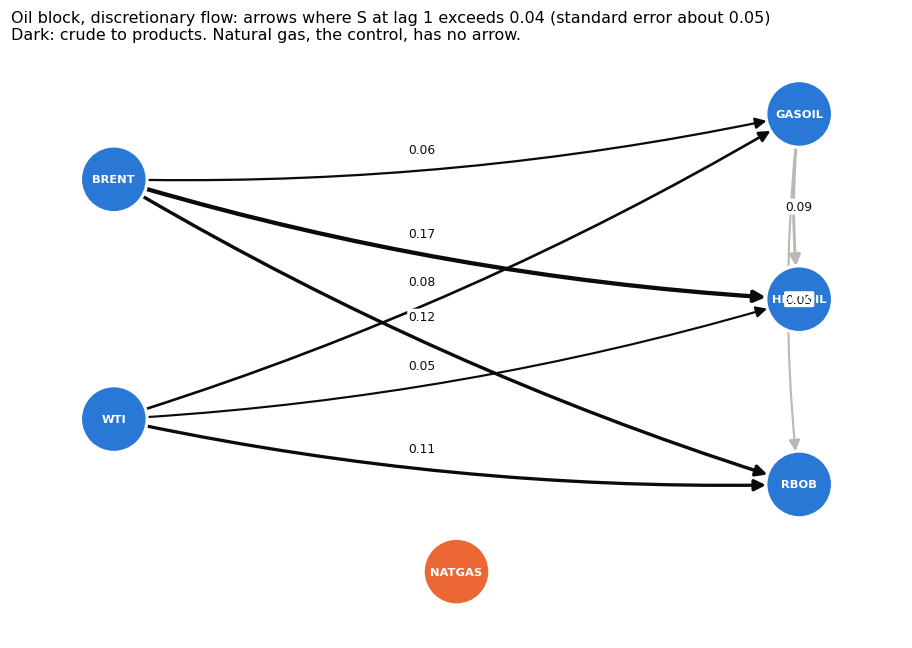

In [8]:
def group_mean(S, leaders, laggers):
    return S[np.ix_([M.index(m) for m in leaders], [M.index(m) for m in laggers])].mean()


PLACEBOS = {"Crude to products": (CRUDE, PRODUCTS), "Natural gas to products": (["NATGAS"], PRODUCTS), "Crude to natural gas": (CRUDE, ["NATGAS"]),
            "Metals to grains": (["GC", "SI", "PL", "PA", "HG"], ["C", "W", "S"]), "Softs to metals": (["KC", "CC", "SB", "CT"], ["GC", "SI", "PL", "PA", "HG"])}
rows = []
for label, (leaders, laggers) in PLACEBOS.items():
    for name in ("disc_pw", "ret_pw"):
        estimate = group_mean(metrics[name]["lag1"], leaders, laggers)
        row = {"Group": label, "Series": name, "Mean S": estimate}
        for null in ("iid", "block4", "local13"):
            key = (name, null)
            if key not in draws:
                draws[key] = ll.permutation_draws(series[name], 1000, null, seed=23)
            d = draws[key]["lag1"]
            null_values = d[:, [M.index(m) for m in leaders]][:, :, [M.index(m) for m in laggers]].mean((1, 2))
            row[f"p, {null}"] = (1 + (np.abs(null_values) >= abs(estimate)).sum()) / (len(null_values) + 1)
        rows.append(row)
display(pd.DataFrame(rows).set_index(["Group", "Series"]))
pairs = pd.DataFrame(metrics["disc_pw"]["lag1"], index=M, columns=M).loc[CRUDE, PRODUCTS]
display(pairs.rename_axis("S, disc_pw, lag 1"))

layout = {"BRENT": (-1, 0.55), "WTI": (-1, -0.55), "GASOIL": (1, 0.85), "HEATOIL": (1, 0.0), "RBOB": (1, -0.85), "NATGAS": (0, -1.25)}
S6 = pd.DataFrame(metrics["disc_pw"]["lag1"], index=M, columns=M).loc[OILGAS, OILGAS]
G6 = nx.DiGraph()
G6.add_nodes_from(OILGAS)
fig, ax = plt.subplots(figsize=(8.4, 6.0))
for a in OILGAS:
    for b in OILGAS:
        if S6.loc[a, b] > 0.04:
            nx.draw_networkx_edges(G6, layout, ax=ax, edgelist=[(a, b)], nodelist=OILGAS, node_size=1900, edge_color=INK if a in CRUDE and b in PRODUCTS else SOFT, width=0.8 + 12 * S6.loc[a, b],
                                   arrows=True, arrowstyle="-|>", arrowsize=15, connectionstyle="arc3,rad=0.06")
            share = 0.45 if a in CRUDE else 0.5
            x, y = (1 - share) * np.array(layout[a]) + share * np.array(layout[b])
            ax.text(x, y, f"{S6.loc[a, b]:.2f}", fontsize=8, ha="center", va="center", color=INK, bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none"))
nx.draw_networkx_nodes(G6, layout, ax=ax, nodelist=OILGAS, node_size=1900, node_color=[COLOR[ll.SECTOR[m]] for m in OILGAS], edgecolors="white", linewidths=2)
nx.draw_networkx_labels(G6, layout, ax=ax, font_size=7.5, font_color="white", font_weight="semibold")
ax.set_title("Oil block, discretionary flow: arrows where S at lag 1 exceeds 0.04 (standard error about 0.05)\nDark: crude to products. Natural gas, the control, has no arrow.", loc="left", fontsize=10.5)
ax.set(xlim=(-1.3, 1.3), ylim=(-1.55, 1.15))
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "network_oil_block.png", dpi=170)
plt.show()

**Reading.** The oil block has more structure than the full panel, but not where we named it in advance.

- **The global test rejects on the five oil markets** at ccf-lag1 (disc_pw p = 0.006 iid, 0.005 local13), and not in returns under the stricter null (p = 0.064 iid, 0.255 local13). Adding natural gas weakens it (0.015, 0.020), and ccf-auc does not reject on flows (0.23-0.94). The links at BH 10% are Brent to heating oil, Brent to RBOB and WTI to RBOB, under both nulls.
- **The named links mostly fail.** On discretionary flow none survives (BH q of at least 0.342), and none of the 30 oil and gas links does either. On raw flow only gasoil to RBOB survives (t = 2.71, q = 0.027), and 3 of the 30.
- **Crude to products holds up as a block.** Mean S is 0.097 (p = 0.001 iid and local13, 0.063 block4), all six pairs are positive (0.05-0.17), and the controls are near zero: natural gas to products -0.003, crude to natural gas -0.008, metals to grains 0.015, softs to metals -0.010. It is absent in returns (0.018, p = 0.34). The direction fits a crude-first story, but we chose this aggregation after seeing the matrix. Section 7 checks whether it forecasts.

The rotation in the comment plays out over months, which a weekly lag cannot see. So we repeat the named links with $h$-week cumulated flows: does the leader's flow over the last $h$ weeks predict the lagger's over the next $h$? Overlapping sums inflate HAC t-statistics, so we also rank each link among all 30 oil and gas links, and add seasonal terms for the two product links.

In [9]:
rows = []
for h in (4, 8, 13):
    all_t = {(a, b): link_test(a, b, "disc", h)["t"] for a, b in ALL_OIL_LINKS}
    p_named = [link_test(a, b, "disc", h)["p"] for a, b in NAMED]
    q_named = ll.bh_qvalues(np.array(p_named))
    for (a, b), q_value in zip(NAMED, q_named):
        fit, seasonal = link_test(a, b, "disc", h), link_test(a, b, "disc", h, harmonics=True)
        rank = sum(abs(v) >= abs(all_t[a, b]) for v in all_t.values())
        rows.append({"h": h, "Link": f"{a} to {b}", "Coefficient": fit["Coefficient"], "t": fit["t"], "p": fit["p"], "BH q, 4 links": q_value,
                     "Rank of |t| among 30": rank, "t with seasonal terms": seasonal["t"]})
    print(f"h={h}: sd of t across the 30 links {np.std(list(all_t.values())):.2f}")
month_scale = pd.DataFrame(rows).set_index(["h", "Link"])
display(month_scale)


def month_checks(leader, lagger, h=8):
    """The link's coefficient by period, and its out-of-sample value: expanding OLS using only targets known at the forecast date."""
    source = frames["disc"]
    data = pd.DataFrame({"y": source[lagger].rolling(h).sum().shift(-h), "leader": source[leader].rolling(h).sum(), "own": source[lagger].rolling(h).sum(),
                         "ret_own": frames["ret"][lagger].rolling(h).sum(), "ret_leader": frames["ret"][leader].rolling(h).sum()}).dropna()
    row = {"Link": f"{leader} to {lagger}", "h": h}
    for period, (start, end) in ll.PERIODS.items():
        part = data.loc[start:end]
        row[f"Coefficient, {period}"] = sm.OLS(part["y"], sm.add_constant(part.drop(columns="y"))).fit().params["leader"]
    sets = {"Without the link": ["own", "ret_own", "ret_leader"], "With the link": ["own", "ret_own", "ret_leader", "leader"]}
    predictions = {name: [] for name in sets}
    test = data.loc["2017":"2025"]
    for date in test.index:
        train = data.loc[:date].iloc[:-h]
        for name, columns in sets.items():
            X = np.c_[np.ones(len(train)), train[columns].to_numpy()]
            beta = np.linalg.lstsq(X, train["y"].to_numpy(), rcond=None)[0]
            predictions[name].append(np.r_[1.0, data.loc[date, columns].to_numpy()] @ beta)
    for name, forecast in predictions.items():
        row[f"R² 2017-2025, {name.lower()}"] = ll.r2_unc(test["y"].to_numpy(), np.array(forecast))
    return row


pd.DataFrame([month_checks("BRENT", "GASOIL"), month_checks("GASOIL", "RBOB")]).set_index(["Link", "h"])

h=4: sd of t across the 30 links 1.03
h=8: sd of t across the 30 links 1.51
h=13: sd of t across the 30 links 1.17


Coefficient      t     p  BH q, 4 links  Rank of |t| among 30  t with seasonal terms
h  Link                                                                                                 
4  WTI to BRENT           0.099  1.583 0.113          0.267                     3                  1.494
   BRENT to WTI          -0.021 -0.388 0.698          0.852                    23                 -1.048
   BRENT to GASOIL        0.098  1.499 0.134          0.267                     5                  1.243
   GASOIL to RBOB        -0.011 -0.186 0.852          0.852                    26                  0.695
8  WTI to BRENT          -0.063 -0.862 0.389          0.518                    18                 -0.954
   BRENT to WTI           0.021  0.314 0.753          0.753                    27                 -0.790
   BRENT to GASOIL        0.216  3.190 0.001          0.003                     2                  3.155
   GASOIL to RBOB        -0.232 -3.576 0.000          0.001                     1                 -2.379
13 WTI to BRENT          -0.093 -0.897 0.370          0.370                    13                 -0.449
   BRENT to WTI           0.069  0.961 0.336          0.370                    12                 -0.174
   BRENT to GASOIL        0.117  1.848 0.065          0.129                     5                  1.398
   GASOIL to RBOB        -0.239 -3.071 0.002          0.009                     1                 -1.559

,,"Coefficient, 2011-2015","Coefficient, 2016-2020","Coefficient, 2021-2025","R² 2017-2025, without the link","R² 2017-2025, with the link"
Link,h,,,,,
BRENT to GASOIL,8,0.462,0.328,-0.125,17.929,13.463
GASOIL to RBOB,8,-0.191,-0.214,-0.239,-2.906,1.287


**Reading.** Month-scale links do not rescue the rotation story.

- **Brent to gasoil at 8 weeks looks strong and fades.** It has t = 3.19 (q = 0.003), and seasonal terms leave it at 3.16. But these t-statistics are inflated: their sd across the 30 links is 1.51 rather than 1, and this link ranks only second. Its coefficient runs 0.46, 0.33, -0.13 across the three periods, and adding it lowers out-of-sample R² from 17.93% to 13.46%. At 4 and 13 weeks it is not significant (q = 0.267, 0.129).
- **Gasoil to RBOB has the wrong sign.** A rotation from gasoil into gasoline implies a positive link, and it is negative: -0.23 at 8 weeks (t = -3.58), stable across periods (-0.19, -0.21, -0.24), and it adds out of sample (-2.91% to 1.29%). It weakens with seasonal terms (t = -2.38 at 8 weeks, -1.56 at 13), so part of it may be seasonal.

The out-of-sample columns use the full-sample discretionary series, which flatters both links.

## 5. Is the network stable?

A network is useful only if it stays the same over time. We estimate it in three periods and compare the sign of each pair, the ranking of leadingness, and Hermitian clusters (the paper's method).

In [10]:
upper_rows, lead_rows, label_rows = [], {}, {}
for name in ("raw_pw", "disc_pw"):
    S_periods = {period: ll.from_ccf(ll.ccf_pearson(frames[name].loc[start:end].to_numpy(), 4)) for period, (start, end) in ll.PERIODS.items()}
    for key, label in {"lag1": "ccf-lag1", "auc_c": "ccf-auc, centred"}.items():
        values = np.array([ll.upper(s[key]) for s in S_periods.values()])
        same = (np.sign(values) == np.sign(values[0])).all(0).sum()
        leadingness = np.array([s[key].sum(1) for s in S_periods.values()])
        spearman = [stats.spearmanr(leadingness[a], leadingness[b])[0] for a, b in [(0, 1), (1, 2), (0, 2)]]
        clusters = [ll.hermitian_rw(s[key], 3)[0] for s in S_periods.values()]
        sectors = [ll.SECTOR[m] for m in M]
        upper_rows.append({"Series": name, "Metric": label, "Pairs with the same sign in all 3 periods": same, "Expected by chance": 153 / 4,
                           "Binomial p": stats.binom.sf(same - 1, 153, 0.25), "Mean Spearman of leadingness": np.mean(spearman),
                           "Mean ARI of clusters across periods": np.mean([ll.ari(clusters[a], clusters[b]) for a, b in [(0, 1), (1, 2), (0, 2)]]),
                           "Mean ARI of clusters with sectors": np.mean([ll.ari(c, sectors) for c in clusters])})
display(pd.DataFrame(upper_rows).set_index(["Series", "Metric"]))
labels, flow_matrix, cluster_lead, _ = ll.hermitian_rw(metrics["disc_pw"]["lag1"], 3)
print("Full-sample clusters of disc_pw, ccf-lag1, leading first:", {k: [M[i] for i in np.flatnonzero(labels == k)] for k in range(3)})
print("Meta-flow between clusters:")
print(pd.DataFrame(flow_matrix).round(3).to_string())

Pairs with the same sign in all 3 periods  Expected by chance  Binomial p  Mean Spearman of leadingness  Mean ARI of clusters across periods  \
Series  Metric                                                                                                                                                           
raw_pw  ccf-lag1                                                 39              38.250       0.475                         0.033                                0.003   
        ccf-auc, centred                                         44              38.250       0.163                        -0.049                                0.077   
disc_pw ccf-lag1                                                 44              38.250       0.163                         0.163                                0.026   
        ccf-auc, centred                                         38              38.250       0.550                        -0.133                                0.027   

                          Mean ARI of clusters with sectors  
Series  Metric                                               
raw_pw  ccf-lag1                                      0.131  
        ccf-auc, centred                              0.110  
disc_pw ccf-lag1                                      0.230  
        ccf-auc, centred                              0.094

Full-sample clusters of disc_pw, ccf-lag1, leading first: {0: ['BRENT', 'WTI', 'GASOIL', 'SB', 'CT'], 1: ['HEATOIL', 'RBOB', 'GC', 'SI', 'PA', 'HG', 'KC', 'CC'], 2: ['NATGAS', 'PL', 'C', 'W', 'S']}
Meta-flow between clusters:
       0      1     2
0  0.000  0.005 0.023
1 -0.005  0.000 0.028
2 -0.023 -0.028 0.000


**Reading.** The network does not persist. Only 38-44 of the 153 pairs keep their sign across all three periods, against 38 by chance (p of at least 0.16, treating pairs as independent). The rank correlation of leadingness between periods is between -0.13 and 0.16, and clusters barely overlap (ARI at most 0.08). Clusters match sectors a little better (ARI of 0.09-0.23), but co-moving markets could produce that without any sector lead-lag, and we did not test it. So the full-sample clusters and the leadingness ranking (silver first, platinum last) are not stable facts.

## 6. The 2026 rotation

The comment says discretionary money rotated from crude into gasoil and gasoline from April, with more moves in July and August. We ask whether the data show it, with three definitions of the non-trend flow, because none is clean.

- **Raw**: the change in MM.
- **Price rule**: the residual on signal flow and vol-scaled return, with coefficients frozen on 2015-2025, so there is no contamination from 2026.
- **NN error**: actual minus the NN nowcast. The NN is fitted to MM itself, so its trend can absorb the very flow we want to measure.

Every window below is ranked against all windows of the same length that end by 2025. All numbers are in thousand contracts.

In [11]:
config = ReplicationConfig(data_dir=REPO_ROOT / "paper_replication" / "data_required", basis="futures_only", train_weeks=104, seed=7, evaluation_end="2026-12-31")
panel, _ = sg.load_weekly_data(config)
decomposition, _ = sg.run_decomposition(panel, config)
nn = decomposition.merge(panel[sg.KEYS + ["actual_change", "mm_std_lag", "panel_date"]], on=sg.KEYS)
nn["predicted_change"] = nn["mm_std_lag"] * (nn["trend_cur"] - nn["trend_prev"])
nn["error"] = nn["actual_change"] - nn["predicted_change"]

z = T.ret / T.ret.rolling(26, min_periods=13).std().shift(1)
frozen = {}
for market in OILGAS:
    d = pd.DataFrame({"y": T.d_mm[market], "flow": T.signal_flow[market], "z": z[market]}).dropna()
    train = d.loc["2015":"2025"]
    frozen[market] = d["y"] - sm.OLS(train["y"], sm.add_constant(train[["flow", "z"]])).fit().predict(sm.add_constant(d[["flow", "z"]]))
flows = {"Raw": T.d_mm[OILGAS].loc["2011-07-12":] / 1e3, "Price rule": pd.DataFrame(frozen).loc["2011-07-12":] / 1e3,
         "NN error": nn.pivot(index="report_week_tuesday", columns="market", values="error")[OILGAS] / 1e3}
PHASES = {"Sep 2025-Feb 2026": ("2025-09-01", "2026-03-02"), "Mar 2026": ("2026-03-03", "2026-03-31"), "Apr-Jun 2026": ("2026-04-01", "2026-06-30"), "Jul-Aug 2026": ("2026-07-01", "2026-08-31")}
display(pd.concat({name: pd.DataFrame({phase: frame.loc[a:b].sum() for phase, (a, b) in PHASES.items()}) for name, frame in flows.items()}).rename_axis(["Flow", "Market"]))


def window_rank(series_, start, end):
    """Percentile of the sum over [start, end] among sums over windows of the same length ending by 2025."""
    window = series_.loc[start:end]
    history = series_.rolling(len(window)).sum().loc[:"2025-12-31"].dropna()
    return window.sum(), 100 * (history < window.sum()).mean()


rows = []
for name, frame in flows.items():
    for market in ("BRENT", "WTI", "GASOIL", "RBOB"):
        total, rank = window_rank(frame[market].dropna(), "2026-04-01", "2026-06-30")
        rows.append({"Flow": name, "Market": market, "Sum, Apr-Jun 2026": total, "Percentile": rank})
display(pd.DataFrame(rows).pivot(index="Market", columns="Flow", values=["Sum, Apr-Jun 2026", "Percentile"]))


def break_row(label, series_, name, drop=None):
    """One break in the mean over the 26 weeks from the war's start, ranked against all 26-week windows, so the search over dates is priced in."""
    series_ = series_.dropna()
    if drop:
        series_ = series_.drop(pd.to_datetime(drop), errors="ignore")
    window = series_.loc["2026-03-03":"2026-08-25"]
    statistic, k = ll.sup_break(window.to_numpy())
    values = series_.loc[:"2025-12-31"].to_numpy()
    history = np.array([abs(ll.sup_break(values[e - len(window):e])[0]) for e in range(len(window), len(values) + 1)])
    return {"Flow": name, "Spread": label, "Weeks": len(window), "Break week": f"{window.index[k]:%Y-%m-%d}", "Mean before": window.iloc[:k].mean(), "Mean after": window.iloc[k:].mean(),
            "Statistic": statistic, "Percentile of |statistic|": 100 * (history < abs(statistic)).mean()}


rows = []
for name, frame in flows.items():
    rows.append(break_row("Gasoil and RBOB minus Brent", frame[["GASOIL", "RBOB"]].mean(axis=1) - frame["BRENT"], name))
    rows.append(break_row("Products minus crude", frame[PRODUCTS].mean(axis=1) - frame[CRUDE].mean(axis=1), name))
for weeks in (["2026-03-03"], ["2026-07-14"]):
    rows.append(break_row(f"Gasoil and RBOB minus Brent, without {weeks[0]}", flows["Price rule"][["GASOIL", "RBOB"]].mean(axis=1) - flows["Price rule"]["BRENT"], "Price rule", weeks))
breaks = pd.DataFrame(rows).set_index(["Flow", "Spread"])
display(breaks)

rolling_rows = []
window_weeks = 26
values = frames["disc_pw"][OILGAS]
ends = values.index[window_weeks - 1:]
rolling = np.array([ll.from_ccf(ll.ccf_pearson(values.iloc[e - window_weeks + 1:e + 1].to_numpy(), 1))["lag1"] for e in range(window_weeks - 1, len(values))])
history = ends <= pd.Timestamp("2025-12-31")
outside, tested = 0, 0
for a_index, a in enumerate(OILGAS):
    for b_index, b in enumerate(OILGAS):
        if a_index < b_index:
            path = rolling[:, a_index, b_index]
            for when in ("2026-02-24", "2026-08-25"):
                value = path[ends.get_loc(pd.Timestamp(when))]
                rank = 100 * (path[history] < value).mean()
                tested += 1
                outside += rank < 2.5 or rank > 97.5
                if {a, b} & {"BRENT"} and {a, b} & {"GASOIL", "RBOB", "WTI"}:
                    rolling_rows.append({"Pair (positive: first leads)": f"{a} to {b}", "Window ending": when, "S": value, "Percentile": rank})
print(f"26-week net S in the oil block: {outside} of {tested} values fall outside the historical 2.5-97.5% range ({tested * 0.05:.1f} expected)")
display(pd.DataFrame(rolling_rows).set_index(["Pair (positive: first leads)", "Window ending"]))

Sep 2025-Feb 2026  Mar 2026  Apr-Jun 2026  Jul-Aug 2026
Flow       Market                                                          
Raw        BRENT               98.566    81.360      -280.921       124.110
           WTI                 43.079     5.647         7.935         2.738
           GASOIL               7.857   -29.005        -7.364        27.248
           HEATOIL            -10.466    -3.451       -10.944         8.160
           RBOB                51.355   -25.337         8.441         7.728
           NATGAS             -31.843     8.259         2.808        -6.865
Price rule BRENT               30.228   -29.757      -238.084        97.211
           WTI                 18.184   -84.976        42.774       -11.982
           GASOIL              -8.235   -70.427         2.451        17.300
           HEATOIL            -20.879   -11.495        -8.611         4.987
           RBOB                39.880   -53.200         8.582         3.636
           NATGAS             -88.292     5.162        -1.059         2.391
NN error   BRENT               -6.804    65.216      -105.554        10.414
           WTI                -39.077    -3.577       112.224       -52.675
           GASOIL             -41.736   -37.687        59.453       -12.233
           HEATOIL            -26.917    -5.829         5.952        -2.617
           RBOB                35.811   -28.501        29.020        -3.334
           NATGAS             -98.461     9.900        -8.663        20.643

Sum, Apr-Jun 2026                     Percentile                  
Flow            NN error Price rule      Raw   NN error Price rule    Raw
Market                                                                   
BRENT           -105.554   -238.084 -280.921     12.633      0.134  1.478
GASOIL            59.453      2.451   -7.364     93.416     48.790 45.699
RBOB              29.020      8.582    8.441     88.256     64.113 63.710
WTI              112.224     42.774    7.935     91.815     74.597 56.452

Weeks  Break week  Mean before  Mean after  Statistic  Percentile of |statistic|
Flow       Spread                                                                                                                           
Raw        Gasoil and RBOB minus Brent                         26  2026-04-07      -21.706       8.326      1.763                     43.912
           Products minus crude                                26  2026-04-07      -12.554       4.008      1.810                     51.436
Price rule Gasoil and RBOB minus Brent                         26  2026-07-14       11.584     -13.612     -1.840                     55.130
           Products minus crude                                26  2026-07-14        6.448      -6.527     -1.620                     39.672
NN error   Gasoil and RBOB minus Brent                         26  2026-04-07      -19.662       6.266      1.913                     54.827
           Products minus crude                                26  2026-04-21      -10.542       3.272      1.928                     55.009
Price rule Gasoil and RBOB minus Brent, without 2026-03-03     25  2026-04-14      -20.751       7.431      2.052                     68.033
           Gasoil and RBOB minus Brent, without 2026-07-14     25  2026-07-21       11.584      -6.668     -1.342                     21.448

26-week net S in the oil block: 2 of 30 values fall outside the historical 2.5-97.5% range (1.5 expected)


S  Percentile
Pair (positive: first leads) Window ending                   
BRENT to WTI                 2026-02-24     0.343      94.191
                             2026-08-25     0.018      54.633
BRENT to GASOIL              2026-02-24     0.354      87.275
                             2026-08-25    -0.125      24.205
BRENT to RBOB                2026-02-24     0.390      82.711
                             2026-08-25     0.634      97.510

**Reading.** The comment's rotation appears in only one of the three measures, and its size is ordinary.

- **Brent's liquidation is the large event.** April-June flow is -281k contracts raw (1.5th percentile), -238k on the price rule (0.1th) and -106k on NN error (12.6th).
- **The product inflows depend on the definition.** On NN error, gasoil gets +59k (93rd percentile) and RBOB +29k (88th). Raw flow shows -7k and +8k (46th, 64th), and the price rule +2k and +9k (49th, 64th). So the inflow appears only after subtracting the NN's estimate of trend selling. Neither measure is clean: the NN is fitted to MM itself, and the price rule is blind when signals are capped, as the products' mostly were from March to August (see `kalman_filter.ipynb`, section 2).
- **An April break holds for two measures of three.** Raw flow and NN error break on 2026-04-07 or 04-21. The price rule breaks on 2026-07-14 with all weeks, on 04-14 without 2026-03-03, and on 07-21 without 2026-07-14, so its date rests on single weeks. The size is ordinary in every case: the 21st-68th percentile of same-length windows, with the search over dates priced in.
- **Lead-lag in 2026 is ordinary.** 2 of 30 rolling values fall outside the historical 2.5-97.5% range, with 1.5 expected.

We can say Brent liquidated in size, and that the data do not establish where that money went. We tested no reason for either.

## 7. Does the network forecast?

The test that matters most. We forecast next week's flow out of sample with the repo's pooled ridge: 104-week window, penalty 0.1, refit weekly, using only information available at the forecast date. Network weights are also past-only: they come from a 260-week window on own-AR innovations, refreshed every 13 weeks, using each market's top three leaders. The benchmark is last week's own change, which gave 5.87% on the earlier 2,820 market-weeks.

Clark-West tests whether a model adds to the nested base model in population. It can reject even when the model's out-of-sample $R^2$ is lower, so we read it next to the $R^2$. The permuted row reruns the network with shuffled node labels, which keeps the flow statistics and breaks the graph.

In [12]:
def weeks_mask(index, start, end):
    return np.asarray((index >= pd.Timestamp(start)) & (index <= pd.Timestamp(end)))


def lagged(frame):
    return frame.shift(1).to_numpy()


EVALUATION = {"2017-2025": ("2017-01-01", "2025-12-31"), "2026": ("2026-01-01", "2026-08-31"), "May-Aug 2026": ("2026-05-01", "2026-08-31")}


def evaluate(label, y, base_forecast, forecast, index, scale, rows, base_label):
    row = {"Model": label, "Base for Clark-West": base_label}
    for sample, (start, end) in EVALUATION.items():
        mask = weeks_mask(index, start, end) & np.isfinite(forecast).all(1) & np.isfinite(base_forecast).all(1) & np.isfinite(y).all(1)
        row[f"R² {sample}"] = ll.r2_unc(y[mask] * scale[mask], forecast[mask] * scale[mask])
        if sample == "2017-2025":
            row["Base R²"] = ll.r2_unc(y[mask] * scale[mask], base_forecast[mask] * scale[mask])
            if base_label:
                row["Clark-West p"] = ll.clark_west(y[mask] * scale[mask], base_forecast[mask] * scale[mask], forecast[mask] * scale[mask])[1]
    rows.append(row)


def race(markets, y_frame, scale_frame, own_frame, title, permutations=100):
    index = y_frame.index
    raw_all = frames["raw"].reindex(index)
    y, scale = y_frame[markets].to_numpy(), scale_frame[markets].to_numpy()
    own = own_frame[markets].to_numpy()
    ret = lagged(Y["sret"].reindex(index)[markets])
    signal = lagged(Y["sf"].reindex(index)[markets])
    graph_source = frames["raw"][markets].to_numpy()
    W, phi, cluster_labels = ll.past_only_weights(graph_source, cluster=True)
    graph_index = frames["raw"].index
    to_frame = lambda values: lagged(pd.DataFrame(values, index=graph_index, columns=markets).reindex(index))
    net = to_frame(ll.message(graph_source, W, phi))
    cluster = to_frame(ll.cluster_feature(graph_source, cluster_labels))
    leave_out = pd.DataFrame({m: (frames["raw"][markets].sum(axis=1) - frames["raw"][m]) / (len(markets) - 1) for m in markets})
    others = lagged(leave_out.reindex(index))
    rows = []
    f_own = ll.pooled_ridge(y, [own])
    f_ret = ll.pooled_ridge(y, [own, ret])
    evaluate("Own lag", y, f_own, f_own, index, scale, rows, "")
    evaluate("Own lag + own return", y, f_own, f_ret, index, scale, rows, "Own lag")
    evaluate("Own lag + own return + signal flow", y, f_own, ll.pooled_ridge(y, [own, ret, signal]), index, scale, rows, "Own lag")
    evaluate("Own lag + network", y, f_own, ll.pooled_ridge(y, [own, net]), index, scale, rows, "Own lag")
    evaluate("Own lag + return + network", y, f_ret, ll.pooled_ridge(y, [own, ret, net]), index, scale, rows, "Own lag + own return")
    evaluate("Own lag + leading-cluster EWMA (the paper's signal)", y, f_own, ll.pooled_ridge(y, [own, cluster]), index, scale, rows, "Own lag")
    evaluate("Own lag + mean of the other markets", y, f_own, ll.pooled_ridge(y, [own, others]), index, scale, rows, "Own lag")
    if set(CRUDE + PRODUCTS) <= set(markets):
        crude = lagged(pd.DataFrame({m: frames["raw"][CRUDE].mean(axis=1) if m in PRODUCTS else 0.0 * frames["raw"][m] for m in markets}).reindex(index))
        evaluate("Own lag + crude flow, products only", y, f_own, ll.pooled_ridge(y, [own, crude]), index, scale, rows, "Own lag")
    lags = lagged(raw_all[markets])
    var = np.column_stack([ll.pooled_ridge(y[:, [j]], [lags[:, [i]] for i in range(len(markets))]) for j in range(len(markets))])
    own_each = np.column_stack([ll.pooled_ridge(y[:, [j]], [lags[:, [j]]]) for j in range(len(markets))])
    evaluate("Ridge VAR on all markets, one regression per market", y, own_each, var, index, scale, rows, "Own lag, per market")
    table = pd.DataFrame(rows).set_index("Model")
    real = ll.r2_unc(*(a[weeks_mask(index, *EVALUATION["2017-2025"]) & np.isfinite(y).all(1)] * scale[weeks_mask(index, *EVALUATION["2017-2025"]) & np.isfinite(y).all(1)] for a in (y, ll.pooled_ridge(y, [own, net]))))
    rng = np.random.default_rng(31)
    placebo = []
    mask = weeks_mask(index, *EVALUATION["2017-2025"]) & np.isfinite(y).all(1)
    for _ in range(permutations):
        shuffled = to_frame(ll.message(graph_source, W, phi, rng.permutation(len(markets))))
        placebo.append(ll.r2_unc(y[mask] * scale[mask], ll.pooled_ridge(y, [own, shuffled])[mask] * scale[mask]))
    placebo = np.array(placebo)
    print(f"{title}: own lag + network R² {real:.2f}; with shuffled node labels mean {placebo.mean():.2f}, 5-95% [{np.quantile(placebo, 0.05):.2f}, {np.quantile(placebo, 0.95):.2f}], rank p {(1 + (placebo >= real).sum()) / (permutations + 1):.2f}")
    return table


pivot = lambda column: nn.pivot(index="report_week_tuesday", columns="market", values=column)
previous = panel[sg.KEYS + ["actual_change"]].pivot(index="report_week_tuesday", columns="market", values="actual_change").shift(1).reindex(pivot("actual_change").index)
y6 = pivot("actual_change") / pivot("mm_std_lag")
own6 = previous / pivot("mm_std_lag")
oil_race = race(OILGAS, y6, pivot("mm_std_lag"), own6, "Six energy markets, contracts", permutations=100)
display(oil_race)
all_race = race(M, frames["raw"], pd.DataFrame(1.0, index=frames["raw"].index, columns=M), frames["raw"].shift(1), "All 18 markets, scaled", permutations=100)
display(all_race)

design = nn.merge((previous / 1).stack().rename("previous_change").rename_axis(sg.KEYS).reset_index(), on=sg.KEYS)
design["normalized_change"] = design["actual_change"] / design["mm_std_lag"]
design["previous_change_scaled"] = design["previous_change"] / design["mm_std_lag"]
repo = sg.common_sample(sg.rolling_ridge(design.dropna(subset=["previous_change_scaled"]), ["previous_change_scaled"], "normalized_change", None, True)[0])
print(f"Parity with the repo's rolling ridge on {len(repo)} market-weeks: {sg.score(repo, 'prediction')['R² (%)']:.2f}%; our array version: {oil_race.loc['Own lag', 'R² 2017-2025']:.2f}%")

Six energy markets, contracts: own lag + network R² 5.40; with shuffled node labels mean 5.19, 5-95% [4.75, 5.56], rank p 0.20


,Base for Clark-West,R² 2017-2025,Base R²,R² 2026,R² May-Aug 2026,Clark-West p
Model,,,,,,
Own lag,,5.872,5.872,0.201,2.514,NaN
Own lag + own return,Own lag,4.177,5.872,2.129,3.954,0.088
Own lag + own return + signal flow,Own lag,3.938,5.872,1.290,2.323,0.044
Own lag + network,Own lag,5.396,5.872,-1.322,1.055,0.235
Own lag + return + network,Own lag + own return,3.875,4.177,0.735,3.219,0.281
Own lag + leading-cluster EWMA (the paper's signal),Own lag,5.435,5.872,-0.458,1.464,0.971
Own lag + mean of the other markets,Own lag,4.960,5.872,-0.443,2.364,0.429
"Own lag + crude flow, products only",Own lag,5.360,5.872,0.119,2.272,0.980
"Ridge VAR on all markets, one regression per market","Own lag, per market",0.380,3.752,-5.047,-12.854,0.043


All 18 markets, scaled: own lag + network R² 5.84; with shuffled node labels mean 5.83, 5-95% [5.77, 5.91], rank p 0.40


,Base for Clark-West,R² 2017-2025,Base R²,R² 2026,R² May-Aug 2026,Clark-West p
Model,,,,,,
Own lag,,5.894,5.894,5.627,6.020,NaN
Own lag + own return,Own lag,7.047,5.894,6.373,8.097,0.000
Own lag + own return + signal flow,Own lag,7.559,5.894,6.744,8.437,0.000
Own lag + network,Own lag,5.842,5.894,5.693,5.914,0.287
Own lag + return + network,Own lag + own return,6.943,7.047,6.522,8.108,0.883
Own lag + leading-cluster EWMA (the paper's signal),Own lag,5.885,5.894,5.295,5.533,0.148
Own lag + mean of the other markets,Own lag,5.749,5.894,5.708,6.463,0.892
"Own lag + crude flow, products only",Own lag,5.787,5.894,5.535,5.912,0.424
"Ridge VAR on all markets, one regression per market","Own lag, per market",-8.976,5.650,-8.120,-5.419,0.370


Parity with the repo's rolling ridge on 2820 market-weeks: 5.87%; our array version: 5.87%


**Reading.** The network does not forecast.

- **Energy.** Our array version matches the repo's 5.87% on the 2,820 market-weeks. Adding the network gives 5.40%, the paper's leading-cluster signal 5.44%, the other markets' mean 4.96%. None reaches a Clark-West p below 0.2.
- **Crude to products has no out-of-sample value**: 5.36%, Clark-West p = 0.98. So the one in-sample structure from section 4 does not carry over.
- **On all 18 markets prices add and the network does not.** Own lag gives 5.89%, adding own return 7.05%, adding signal flow too 7.56% (Clark-West p below 0.001). Adding the network to own lag gives 5.84%, and on top of the return it gives 6.94% against 7.05% (p = 0.88).
- **Shuffled graphs do about as well.** On six markets the network gives 5.40% against a shuffled mean of 5.19% (5-95%: 4.75-5.56, rank p = 0.20). On 18 markets it gives 5.84% against 5.83% (rank p = 0.40).
- **Clark-West needs reading with care.** The ridge VAR gets p = 0.043 on six markets while its R² falls from 3.75% to 0.38%. In energy, return also lowers R² (5.87% to 4.18%) with p = 0.088.
- **2026 does not change this.** On six markets own lag gives 0.20%, adding the return 2.13%, and adding the network -1.32%.

Next, does the network help the NN nowcast of this week's flow? We use the repo's error correction: a ridge on the NN's own past errors and on lagged network information, against the 44.90% benchmark.

In [13]:
errors = (nn.pivot(index="report_week_tuesday", columns="market", values="error") / pivot("mm_std_lag"))[OILGAS]
err_values = errors.to_numpy()
start_row = np.flatnonzero(np.isfinite(err_values).all(1))[0]
W_err, phi_err, _ = ll.past_only_weights(err_values[start_row:], minimum=52, window=104)
net_err = pd.DataFrame(ll.message(err_values[start_row:], W_err, phi_err), index=errors.index[start_row:], columns=OILGAS)
W_raw, phi_raw, _ = ll.past_only_weights(frames["raw"].to_numpy())
net_raw = pd.DataFrame(ll.message(frames["raw"].to_numpy(), W_raw, phi_raw), index=frames["raw"].index, columns=M)[OILGAS]
leave_out = pd.DataFrame({m: (errors.sum(axis=1) - errors[m]) / 5 for m in OILGAS})


def attach(design, frame, name):
    return design.merge(frame.shift(1).stack().rename(name).rename_axis(sg.KEYS).reset_index(), on=sg.KEYS, how="left")


features = design
for frame, name in [(errors, "own_error_lag"), (net_err, "network_of_errors"), (net_raw, "network_of_flows"), (leave_out, "others_error_lag")]:
    features = attach(features, frame, name)
benchmark = sg.common_sample(features)
print(f"NN alone, 2017-2025: {sg.score(benchmark)['R² (%)']:.2f}% on {len(benchmark)} market-weeks")
rows, corrected = [], {}
for label, columns in {"Own lagged NN error": ["own_error_lag"], "Network of NN errors": ["network_of_errors"], "Network of flows": ["network_of_flows"], "Mean of the others' errors": ["others_error_lag"],
                       "Own error + network of errors": ["own_error_lag", "network_of_errors"], "Own error + network of flows": ["own_error_lag", "network_of_flows"]}.items():
    out = sg.error_correction(features.dropna(subset=columns), columns, pooled=True)
    corrected[label] = out
    sample = sg.common_sample(out).merge(benchmark[sg.KEYS], on=sg.KEYS)
    base = sample["predicted_change"]
    weekly = ((sample["actual_change"] - base) ** 2 - ((sample["actual_change"] - sample["corrected_change"]) ** 2 - (base - sample["corrected_change"]) ** 2)).groupby(sample["report_week_tuesday"]).sum()
    t = ll.nw_t(weekly.to_numpy())
    may = sg.common_sample(out, "2026-05-01", "2026-08-31")
    rows.append({"Added to the NN": label, "Weeks": len(sample), "NN on the same rows": sg.score(sample)["R² (%)"], "Corrected": sg.score(sample, "corrected_change")["R² (%)"],
                 "Clark-West p": stats.norm.sf(t), "NN, May-Aug 2026": sg.score(may)["R² (%)"], "Corrected, May-Aug 2026": sg.score(may, "corrected_change")["R² (%)"]})
display(pd.DataFrame(rows).set_index("Added to the NN"))
own_fix = sg.common_sample(corrected["Own lagged NN error"], "2017-01-01", "2026-08-31")
by_year = own_fix.groupby(own_fix["report_week_tuesday"].dt.year).apply(lambda d: sg.score(d, "corrected_change")["R² (%)"] - sg.score(d)["R² (%)"], include_groups=False)
by_year.rename("R² gain from the own lagged NN error, points").rename_axis("Year").to_frame().T

NN alone, 2017-2025: 44.90% on 2820 market-weeks


,Weeks,NN on the same rows,Corrected,Clark-West p,"NN, May-Aug 2026","Corrected, May-Aug 2026"
Added to the NN,,,,,,
Own lagged NN error,2814,44.965,46.555,0.000,43.457,43.601
Network of NN errors,2508,44.831,44.637,0.433,43.457,43.150
Network of flows,2820,44.903,43.714,0.627,43.457,42.272
Mean of the others' errors,2814,44.965,45.121,0.008,43.457,43.673
Own error + network of errors,2508,44.831,45.935,0.002,43.457,43.252
Own error + network of flows,2814,44.965,45.541,0.005,43.457,42.165


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"R² gain from the own lagged NN error, points",2.543,5.494,0.915,5.152,-1.237,-0.853,-0.592,0.495,-0.531,-1.666


**Reading.** The network does not help the nowcast either. The NN's own lagged error adds 1.59 points (44.97% to 46.56%, Clark-West p below 0.001), but that gain was earned in 2017-2020 (+0.9 to +5.5 a year), and since then it runs from -1.7 to +0.5. A network of flows lowers R² by 1.19 points and a network of NN errors by 0.19. The other markets' mean error adds 0.16 (p = 0.008). May-August 2026 sees no rescue: 43.46% rises to 43.67% at best.

## 8. A neural network on the graph

"Network" can also mean a neural network, so we also try the smallest version that uses the graph: one message-passing layer with the paper's reaction function,

$$\hat y_{j,t+1} = \beta\, y_{j,t} + \gamma\, R\Big(\sum_{i \in N(j)} \theta_{ij}\, e_{i,t}\Big), \qquad R(u) = u\, e^{(1-u^2)/2}.$$

$N(j)$ holds $j$'s top three leaders in a past-only lead-lag matrix, and $\theta$ starts at the normalized weights and is then learned, with a 260-week window and a refit every 26 weeks. We compare it with the same graph with fixed weights (linear, two parameters), with learned weights but no reaction function, and with the message-passing model on graphs with shuffled node labels (10 draws).

In [14]:
class TinyMessagePassing(tnn.Module):
    def __init__(self, weights, mask, nonlinear):
        super().__init__()
        self.mask = torch.tensor(mask, dtype=torch.float32)
        self.theta = tnn.Parameter(torch.tensor(weights, dtype=torch.float32))
        self.own = tnn.Parameter(torch.tensor(0.2))
        self.gamma = tnn.Parameter(torch.tensor(0.05))
        self.nonlinear = nonlinear

    def forward(self, e, own):
        message = e @ (self.theta * self.mask)
        return self.own * own + self.gamma * (reaction(message) if self.nonlinear else message)


def fit_tiny(e, own, target, weights, mask, nonlinear, l2=0.01, epochs=250, lr=0.02):
    torch.manual_seed(7)
    model = TinyMessagePassing(weights, mask, nonlinear)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X, O, Y_ = (torch.tensor(a, dtype=torch.float32) for a in (e, own, target))
    for _ in range(epochs):
        optimizer.zero_grad(set_to_none=True)
        loss = ((Y_ - model(X, O)) ** 2).mean() + l2 * ((model.theta * model.mask) ** 2).sum() / max(mask.sum(), 1)
        loss.backward()
        optimizer.step()
    return model


def run_graph(kind, y, step=26, window=260, minimum=260, permutation=None):
    """Rolling forecast of y_{t+1} at t. kind: own, linear (fixed graph), learned, message."""
    T, p = y.shape
    forecast = np.full((T, p), np.nan)
    state = None
    for n, t in enumerate(range(minimum, T - 1)):
        Y_ = y[max(0, t - window + 1):t + 1]
        if n % step == 0:
            phi = (Y_[:-1] * Y_[1:]).sum(0) / (Y_[:-1] ** 2).sum(0)
            e = Y_[1:] - phi * Y_[:-1]
            S = ll.from_ccf(ll.ccf_pearson(e, 1))["lag1"]
            if permutation is not None:
                S = S[np.ix_(permutation, permutation)]
            weights, mask = ll.top_k_graph(S, 3)
            X, own, target = e[:-1], Y_[1:-1], Y_[2:]
            if kind == "own":
                state = own.ravel() @ target.ravel() / (own.ravel() @ own.ravel())
            elif kind == "linear":
                A = np.c_[own.ravel(), (X @ weights).ravel()]
                state = np.linalg.lstsq(A, target.ravel(), rcond=None)[0]
            else:
                state = fit_tiny(X, own, target, weights, mask, kind == "message")
        e_t = y[t] - phi * y[t - 1]
        if kind == "own":
            forecast[t + 1] = state * y[t]
        elif kind == "linear":
            forecast[t + 1] = state[0] * y[t] + state[1] * (e_t @ weights)
        else:
            with torch.no_grad():
                forecast[t + 1] = state(torch.tensor(e_t[None], dtype=torch.float32), torch.tensor(y[t][None], dtype=torch.float32)).numpy()[0]
    return forecast


rows = []
for title, markets in {"Six energy markets": OILGAS, "All 18 markets": M}.items():
    y = frames["raw"][markets].to_numpy()
    index = frames["raw"].index
    results = {kind: run_graph(kind, y) for kind in ("own", "linear", "learned", "message")}
    rng = np.random.default_rng(41)
    placebo = [run_graph("message", y, permutation=rng.permutation(len(markets))) for _ in range(10)]
    mask = weeks_mask(index, *EVALUATION["2017-2025"]) & np.isfinite(results["message"]).all(1)
    mask_2026 = weeks_mask(index, *EVALUATION["2026"]) & np.isfinite(results["message"]).all(1)
    loss = lambda f: ((y[mask] - f[mask]) ** 2).sum(1)
    for kind, label in {"own": "Own lag", "linear": "Fixed graph, linear", "learned": "Learned edges, linear", "message": "Message passing"}.items():
        difference = loss(results["linear"]) - loss(results[kind])
        rows.append({"Panel": title, "Model": label, "R² 2017-2025": ll.r2_unc(y[mask], results[kind][mask]), "R² 2026": ll.r2_unc(y[mask_2026], results[kind][mask_2026]),
                     "Diebold-Mariano t vs fixed graph": ll.nw_t(difference) if kind != "linear" else np.nan})
    rows.append({"Panel": title, "Model": "Message passing, shuffled graph (mean of 10)", "R² 2017-2025": np.mean([ll.r2_unc(y[mask], f[mask]) for f in placebo]),
                 "R² 2026": np.mean([ll.r2_unc(y[mask_2026], f[mask_2026]) for f in placebo])})
neural = pd.DataFrame(rows).set_index(["Panel", "Model"])
neural

R² 2017-2025  R² 2026  Diebold-Mariano t vs fixed graph
Panel              Model                                                                                                
Six energy markets Own lag                                              3.836    0.561                             1.368
                   Fixed graph, linear                                  3.021   -0.422                               NaN
                   Learned edges, linear                                2.361   -0.124                            -2.102
                   Message passing                                      2.380   -1.883                            -2.058
                   Message passing, shuffled graph (mean of 10)         2.829   -1.454                               NaN
All 18 markets     Own lag                                              5.142    5.166                             3.462
                   Fixed graph, linear                                  4.101    4.230                               NaN
                   Learned edges, linear                                3.459    5.499                            -3.190
                   Message passing                                      3.252    3.274                            -3.446
                   Message passing, shuffled graph (mean of 10)         3.479    4.104                               NaN

**Reading.** The neural version loses. On six markets message passing gives 2.38%, against 3.02% for the fixed graph and 3.84% for own lag. On 18 markets it gives 3.25%, 4.10% and 5.14%. It is significantly worse than the fixed linear graph (Diebold-Mariano t = -2.06 and -3.45) and no better than itself on shuffled graphs (2.83% and 3.48%). This is one configuration, not a search, but since the two-parameter graph already loses to own lag, more flexibility has little to find.

## Save results

In [15]:
tests.to_csv(OUTPUT / "global_tests.csv")
survivors.to_csv(OUTPUT / "filtered_network_edges.csv", index=False)
ll.edge_table(G_raw).to_csv(OUTPUT / "naive_network_edges.csv", index=False)
pd.DataFrame(metrics["disc_pw"]["lag1"], index=M, columns=M).to_csv(OUTPUT / "leadlag_matrix_disc_pw.csv")
named_links.to_csv(OUTPUT / "named_links.csv")
month_scale.to_csv(OUTPUT / "month_scale_links.csv")
breaks.to_csv(OUTPUT / "rotation_breaks.csv")
oil_race.to_csv(OUTPUT / "forecast_race_oil.csv")
all_race.to_csv(OUTPUT / "forecast_race_all.csv")
neural.to_csv(OUTPUT / "neural_horse_race.csv")
print(sorted(path.name for path in OUTPUT.iterdir()))

['filtered_network_edges.csv', 'forecast_race_all.csv', 'forecast_race_oil.csv', 'global_tests.csv', 'leadlag_matrices.png', 'leadlag_matrix_disc_pw.csv', 'month_scale_links.csv', 'naive_network_edges.csv', 'named_links.csv', 'network_naive_vs_filtered.png', 'network_oil_block.png', 'neural_horse_race.csv', 'rotation_breaks.csv']


## References

- Bennett, S., Cucuringu, M. and Reinert, G. (2022). Lead-lag detection and network clustering for multivariate time series with an application to the US equity market. *Machine Learning*, 111(12), 4497-4538. PDF in `references/`.
- Benjamini, Y. and Hochberg, Y. (1995). Controlling the false discovery rate. *Journal of the Royal Statistical Society B*, 57(1).
- Clark, T. E. and West, K. D. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics*, 138(1).
- Haugh, L. D. (1976). Checking the independence of two covariance-stationary time series. *Journal of the American Statistical Association*, 71(354).
- Zhu, X., Pan, R., Li, G., Liu, Y. and Wang, H. (2017). Network vector autoregression. *Annals of Statistics*, 45(3).
- Sun, Bouchouev and Fattouh (2026), the Strait of Hormuz comment, in `references/`.